# IMPORT

In [2]:
%load_ext autoreload
%autoreload 2

import re

import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

from configs import DataLoaders, SearchConfig, TrainConfig
from dataset import NamesDataset
from experiments import (
    build_attention_translation_model,
    build_translation_model,
    combine_callbacks,
    generate_names,
    make_attention_callback,
    make_translation_callback,
    run,
    suggest_attention_params,
    suggest_encoder_params,
    suggest_transformer_params,
    summarize_results,
)

from models import Encoder, TransformerSeq2Seq
from plots import plot_attention, plot_positional_encoding
from train import generation_step, translation_step

/home/apkin/school21/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# DATA LOADING AND PREPROCESSING

In [3]:
df = pd.read_csv(
    "../datasets/baby_names.csv",
    delimiter=';'
)
df.head()

,latin,cyrillic,gender
0,John,Джон,boy
1,William,Уильям,boy
2,James,Джеймс,boy
3,Charles,Чарльз,boy
4,George,Джордж,boy


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6782 entries, 0 to 6781
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   latin     6782 non-null   str  
 1   cyrillic  6782 non-null   str  
 2   gender    6782 non-null   str  
dtypes: str(3)
memory usage: 159.1 KB


check balance of gender

In [5]:
df['gender'].value_counts(normalize=True)

gender
boy     0.506783
girl    0.493217
Name: proportion, dtype: float64

convert names to lowercase

In [6]:
df[['latin', 'cyrillic']] = df[['latin', 'cyrillic']].map(str.lower)

extend each name with 'start of name' prefix, 'end of name' postfix and pad the name up to the maximum length

In [7]:
df['extended_latin'] = '<SOS>' + df['latin'] + '<EOS>'
df['extended_cyrillic'] = '<SOS>' + df['cyrillic'] + '<EOS>'

df

,latin,cyrillic,gender,extended_latin,extended_cyrillic
0,john,джон,boy,<SOS>john<EOS>,<SOS>джон<EOS>
1,william,уильям,boy,<SOS>william<EOS>,<SOS>уильям<EOS>
2,james,джеймс,boy,<SOS>james<EOS>,<SOS>джеймс<EOS>
3,charles,чарльз,boy,<SOS>charles<EOS>,<SOS>чарльз<EOS>
4,george,джордж,boy,<SOS>george<EOS>,<SOS>джордж<EOS>
...,...,...,...,...,...
6777,laylah,лейла,girl,<SOS>laylah<EOS>,<SOS>лейла<EOS>
6778,carleigh,карли,girl,<SOS>carleigh<EOS>,<SOS>карли<EOS>
6779,kenley,кенли,girl,<SOS>kenley<EOS>,<SOS>кенли<EOS>
6780,sloane,слоан,girl,<SOS>sloane<EOS>,<SOS>слоан<EOS>


Create the array of tokens (letters and special symbols) that will be used to encode each name. Create a mapping from token to integer id and vice versa.

In [8]:
special_tokens = ['<PAD>', '<SOS>', '<EOS>']
unique_latin = sorted(list(set(''.join(df['latin']))))
unique_cyrillic = sorted(list(set(''.join(df['cyrillic']))))

tokens_latin = special_tokens + unique_latin
tokens_cyrillic = special_tokens + unique_cyrillic

latin_to_id = {token : idx for idx, token in enumerate(tokens_latin)}
id_to_latin = {idx : token for idx, token in enumerate(tokens_latin)}

cyrillic_to_id = {token : idx for idx, token in enumerate(tokens_cyrillic)}
id_to_cyrillic = {idx : token for idx, token in enumerate(tokens_cyrillic)}

represent each name as a sequence of integers using the mapping. Each sequence should have the same length.

In [9]:
token_pattern = re.compile(r'<[^>]+>|.')

def encode_name(name, token_to_id, token_pattern, max_length):
    name_tokens = token_pattern.findall(name)

    encoded_name = [token_to_id[token] for token in name_tokens]
    if len(encoded_name) < max_length + 2:
        encoded_name += [token_to_id['<PAD>']] * (max_length - len(encoded_name) + 2)

    return encoded_name

max_latin = df['latin'].str.len().max()
max_cyrillic = df['cyrillic'].str.len().max()

df['encoded_latin'] = df['extended_latin'].map(lambda x: encode_name(x, token_to_id=latin_to_id, token_pattern=token_pattern, max_length=max_latin))
df['encoded_cyrillic'] = df['extended_cyrillic'].map(lambda x: encode_name(x, token_to_id=cyrillic_to_id, token_pattern=token_pattern, max_length=max_cyrillic))

df

,latin,cyrillic,gender,extended_latin,extended_cyrillic,encoded_latin,encoded_cyrillic
0,john,джон,boy,<SOS>john<EOS>,<SOS>джон<EOS>,"[1, 12, 17, 10, 16, 2, 0, 0, 0, 0, 0, 0, 0]","[1, 7, 9, 17, 16, 2, 0, 0, 0, 0, 0, 0, 0, 0]"
1,william,уильям,boy,<SOS>william<EOS>,<SOS>уильям<EOS>,"[1, 25, 11, 14, 14, 11, 3, 15, 2, 0, 0, 0, 0]","[1, 22, 11, 14, 29, 32, 15, 2, 0, 0, 0, 0, 0, 0]"
2,james,джеймс,boy,<SOS>james<EOS>,<SOS>джеймс<EOS>,"[1, 12, 3, 15, 7, 21, 2, 0, 0, 0, 0, 0, 0]","[1, 7, 9, 8, 12, 15, 20, 2, 0, 0, 0, 0, 0, 0]"
3,charles,чарльз,boy,<SOS>charles<EOS>,<SOS>чарльз<EOS>,"[1, 5, 10, 3, 20, 14, 7, 21, 2, 0, 0, 0, 0]","[1, 26, 3, 19, 14, 29, 10, 2, 0, 0, 0, 0, 0, 0]"
4,george,джордж,boy,<SOS>george<EOS>,<SOS>джордж<EOS>,"[1, 9, 7, 17, 20, 9, 7, 2, 0, 0, 0, 0, 0]","[1, 7, 9, 17, 19, 7, 9, 2, 0, 0, 0, 0, 0, 0]"
...,...,...,...,...,...,...,...
6777,laylah,лейла,girl,<SOS>laylah<EOS>,<SOS>лейла<EOS>,"[1, 14, 3, 27, 14, 3, 10, 2, 0, 0, 0, 0, 0]","[1, 14, 8, 12, 14, 3, 2, 0, 0, 0, 0, 0, 0, 0]"
6778,carleigh,карли,girl,<SOS>carleigh<EOS>,<SOS>карли<EOS>,"[1, 5, 3, 20, 14, 7, 11, 9, 10, 2, 0, 0, 0]","[1, 13, 3, 19, 14, 11, 2, 0, 0, 0, 0, 0, 0, 0]"
6779,kenley,кенли,girl,<SOS>kenley<EOS>,<SOS>кенли<EOS>,"[1, 13, 7, 16, 14, 7, 27, 2, 0, 0, 0, 0, 0]","[1, 13, 8, 16, 14, 11, 2, 0, 0, 0, 0, 0, 0, 0]"
6780,sloane,слоан,girl,<SOS>sloane<EOS>,<SOS>слоан<EOS>,"[1, 21, 14, 17, 3, 16, 7, 2, 0, 0, 0, 0, 0]","[1, 20, 14, 17, 3, 16, 2, 0, 0, 0, 0, 0, 0, 0]"


Split the dataset into training, valid, and test parts (take 80-10-10%)

In [10]:
df_train, df_temp = train_test_split(
    df,
    test_size=0.2,
    random_state=21
)

df_valid, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=21
)

del df_temp

make datasets and dataloaders

In [11]:
device = torch.device('cuda')

train_dataset = NamesDataset(df_train['encoded_latin'], df_train['encoded_cyrillic'], device=device)
valid_dataset = NamesDataset(df_valid['encoded_latin'], df_valid['encoded_cyrillic'], device=device)
test_dataset = NamesDataset(df_test['encoded_latin'], df_test['encoded_cyrillic'], device=device)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    )

valid_loader = DataLoader(
    valid_dataset,
    batch_size=256,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
)

# RNN Encoder

make configs

In [12]:
loaders = DataLoaders(
    train=train_loader,
    valid=valid_loader,
    test=test_loader,
)

train_config = TrainConfig(
    device=device,
    epochs=100,
    patience=5,
    verbose=1,
)

search_config = SearchConfig(
    n_trials=1,
    n_jobs=1,
    plot_importances=False,
)

fixed_model_params = {
    'vocab_size': len(latin_to_id),
    'pad_idx': latin_to_id['<PAD>'],
}


Experiment: encoder_gru


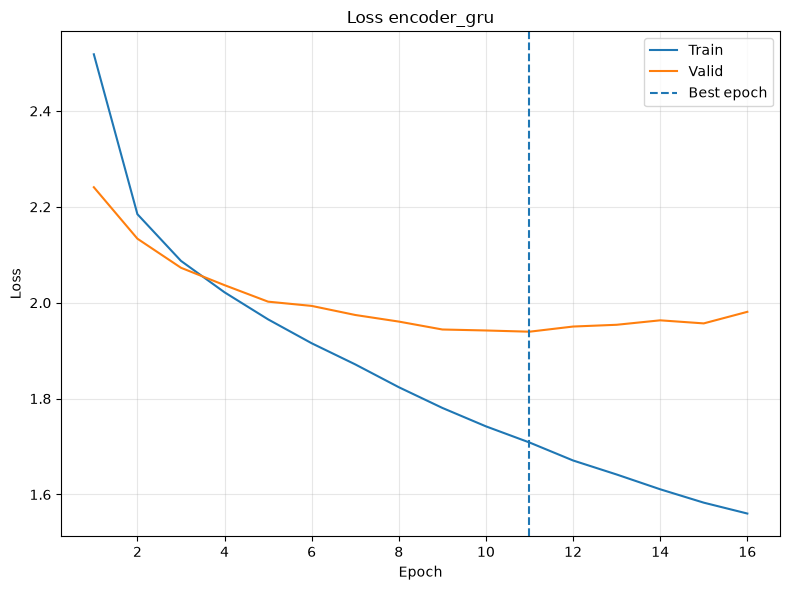

Experiment: encoder_gru
Best epoch: 11/16 completed
Best validation loss: 1.9396
Test loss: 1.9618
Test perplexity: 7.1119


In [13]:
encoder_result = run(
    name='encoder_gru',
    suggest_params=suggest_encoder_params,
    build_model=Encoder,
    fixed_model_params=fixed_model_params,
    loaders=loaders,
    step_fn=generation_step,
    pad_idx=latin_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
)

Generate names using the trained model.

In [14]:
names_prefix = ['', 'a', 'n', 'albe', 'poli']
temperature = [0.5, 1, 2]

generate_names(id_to_token=id_to_latin,
               model=encoder_result['model'],
               prefixes=names_prefix,
               temperatures=temperature,
               token_to_id=latin_to_id,
               train_df=df_train)

,prefix,temperature,name,in_train
0,,0.5,marina,True
1,,1.0,ricky,True
2,,2.0,colusb,False
3,a,0.5,adelle,True
4,a,1.0,adry,False
5,a,2.0,ariolfer,False
6,n,0.5,norine,True
7,n,1.0,nella,True
8,n,2.0,nause,False
9,albe,0.5,albertine,True


# RNN Machine Translation

In [15]:
results = {}

In [16]:
translation_fixed_params = {
    'pretrained_encoder' : encoder_result['model'],
    'vocab_size' : len(cyrillic_to_id),
    'pad_idx' : cyrillic_to_id['<PAD>'],
}

callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)


Experiment: gru_translation


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20,Epoch 25,Epoch 30
train,dijon,дижон,джони,джорин,диксон,дион,диксон,диксон
train,linden,линден,линден,линден,линден,линден,линден,линден
train,stoney,стоуни,стони,тони,тони,тони,тони,стоуни
train,rhea,рея,рейа,рейа,рейа,рейа,рея,рея
train,worley,уорли,кэйли,уэйли,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джейсон,джемантон,джеймон,джеймон,джеманон,джеймон
valid,tyrel,тайрел,дерил,дейли,тайрел,тайрел,тайрел,тейрел
valid,eleonore,элеонора,лореро,аноре,алорен,алорен,анноре,эленор
valid,madelyn,меделин,делини,делинили,мэдлин,мэдилин,мэделин,меделин
valid,jewell,джуэлл,дженель,дженелл,дженелл,джейл,джейл,дженелл


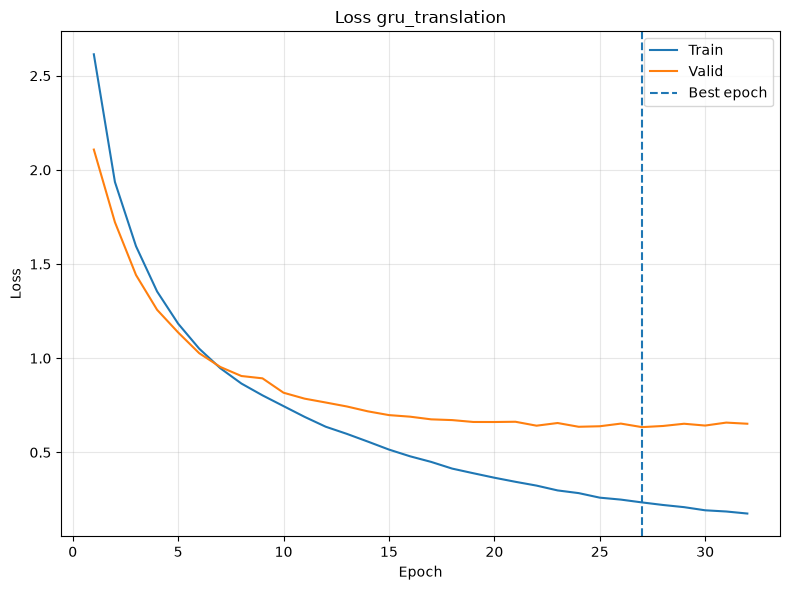

Experiment: gru_translation
Best epoch: 27/32 completed
Best validation loss: 0.6340
Test loss: 0.5892
Test perplexity: 1.8025


In [17]:
seq2seq_result = run(
    name='gru_translation',
    suggest_params=suggest_encoder_params,
    build_model=build_translation_model,
    fixed_model_params=translation_fixed_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[seq2seq_result['name']] = seq2seq_result

Translations generally improve during training, with more exact matches in both the training and validation examples. Many predictions look like plausible names, even when they differ from the expected translations. However, some errors persist, and individual predictions do not improve consistently across epochs.

# Attention Machine Translation

In [18]:
translation_fixed_params = {
    'pretrained_encoder' : encoder_result['model'],
    'vocab_size' : len(cyrillic_to_id),
    'pad_idx' : cyrillic_to_id['<PAD>'],
}

callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)


Experiment: gru_attention_translation


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20,Epoch 25,Epoch 30
train,dijon,дижон,дивон,дикон,диджон,дижон,дижон,дижон
train,linden,линден,линден,линден,линден,линден,линден,линден
train,stoney,стоуни,стон,стони,стони,стони,стони,стоуни
train,rhea,рея,реа,реа,реа,реа,реа,рея
train,worley,уорли,урли,вийли,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джеймесон,джесон,джамесон,джамесон,джеймесон,джеймесон
valid,tyrel,тайрел,тайри,тайрел,тайрел,тайрел,тайрел,тайрел
valid,eleonore,элеонора,элеорео,элеонор,элеонор,элеонор,элеонор,элеонор
valid,madelyn,меделин,маделин,маделин,маделин,мэделин,мэделин,мэделин
valid,jewell,джуэлл,джелль,джелль,джелл,джуэлл,джуэлл,джуэлл


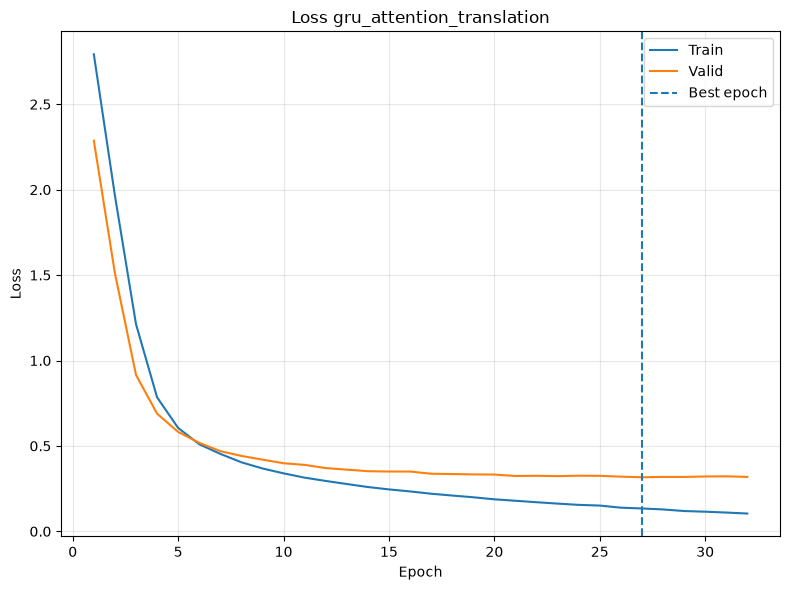

Experiment: gru_attention_translation
Best epoch: 27/32 completed
Best validation loss: 0.3164
Test loss: 0.3004
Test perplexity: 1.3504


In [19]:
attention_seq2seq_result = run(
    name='gru_attention_translation',
    suggest_params=suggest_attention_params,
    build_model=build_attention_translation_model,
    fixed_model_params=translation_fixed_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[attention_seq2seq_result['name']] = attention_seq2seq_result

In [20]:
attention_seq2seq_result['model'].translate(
    name='Archibald',
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
)

'арчибальд'

The attention model achieves lower validation loss, test loss, and test perplexity than the basic encoder–decoder. The selected translations also show more correct names.

# Positional Encoding

### Encoder with sinusoidal PE

In [21]:
sinusoidal_encoder_params = {
    'vocab_size': len(latin_to_id),
    'pad_idx': latin_to_id['<PAD>'],
    'positional_encoding': 'sinusoidal',
}

train_config = TrainConfig(
    device=device,
    epochs=100,
    patience=5,
    verbose=1,
)


Experiment: encoder_gru_sinusoidal


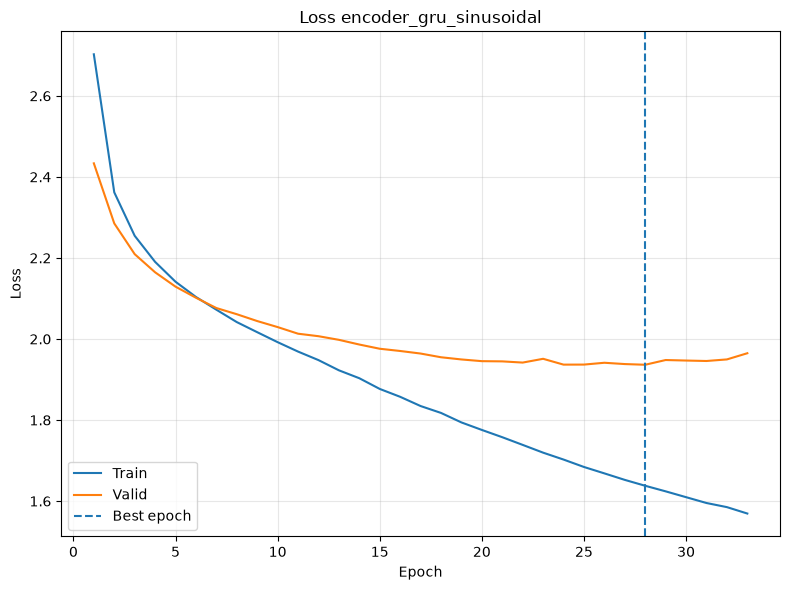

Experiment: encoder_gru_sinusoidal
Best epoch: 28/33 completed
Best validation loss: 1.9364
Test loss: 1.9656
Test perplexity: 7.1391


In [22]:
sinusoidal_encoder_result = run(
    name='encoder_gru_sinusoidal',
    suggest_params=suggest_encoder_params,
    build_model=Encoder,
    fixed_model_params=sinusoidal_encoder_params,
    loaders=loaders,
    step_fn=generation_step,
    pad_idx=latin_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
)

## decoder with sinusoidal PE

In [23]:
train_config = TrainConfig(
    device=device,
    epochs=100,
    patience=5,
    verbose=1,
)

In [24]:
sinusoidal_translation_params = {
    'pretrained_encoder': sinusoidal_encoder_result['model'],
    'vocab_size': len(cyrillic_to_id),
    'pad_idx': cyrillic_to_id['<PAD>'],
    'positional_encoding': 'sinusoidal',
}

### seq2seq


Experiment: gru_translation_sinusoidal


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20
train,dijon,дижон,дойдон,дион,дион,дижон
train,linden,линден,линден,линден,линден,линден
train,stoney,стоуни,тони,стони,стони,стоуни
train,rhea,рея,рей,река,рея,рея
train,worley,уорли,дерли,уорли,уорли,уорли
valid,jameson,джеймсон,джемесон,джемсион,джеймесон,джеймесон
valid,tyrel,тайрел,торел,торель,торель,джарель
valid,eleonore,элеонора,эльфоред,эленор,эленоре,эленор
valid,madelyn,меделин,джейлин,мэдилин,мэдилин,мэдилин
valid,jewell,джуэлл,джерле,джейле,джерель,джейел


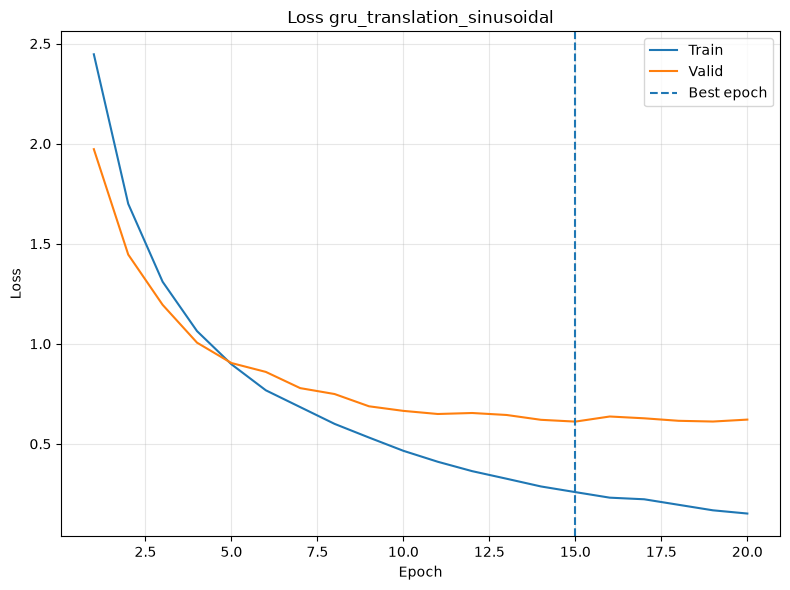

Experiment: gru_translation_sinusoidal
Best epoch: 15/20 completed
Best validation loss: 0.6113
Test loss: 0.5998
Test perplexity: 1.8218


In [25]:
callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

sinusoidal_seq2seq_result = run(
    name='gru_translation_sinusoidal',
    suggest_params=suggest_encoder_params,
    build_model=build_translation_model,
    fixed_model_params=sinusoidal_translation_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[sinusoidal_seq2seq_result['name']] = sinusoidal_seq2seq_result

### attention seq2seq


Experiment: gru_attention_translation_sinusoidal


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20,Epoch 25,Epoch 30
train,dijon,дижон,дидон,диджон,диджон,диджон,диджон,диджон
train,linden,линден,линден,линден,линден,линден,линден,линден
train,stoney,стоуни,стони,стони,стони,стони,стони,стони
train,rhea,рея,реа,реа,реа,рея,рея,рея
train,worley,уорли,уорли,уорли,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джесесон,джамсон,джамсон,джамсон,джамсон,джеймсон
valid,tyrel,тайрел,тайрел,тайрел,тайрель,тайрел,тайрел,тайрель
valid,eleonore,элеонора,элеонор,элеонор,элеоноре,элеонор,элеонор,элеонор
valid,madelyn,меделин,маделин,маделин,маделин,мэйделин,мэлин,мэйделин
valid,jewell,джуэлл,джеллл,джеллл,джеллл,джевелл,джуэлл,джуэлл


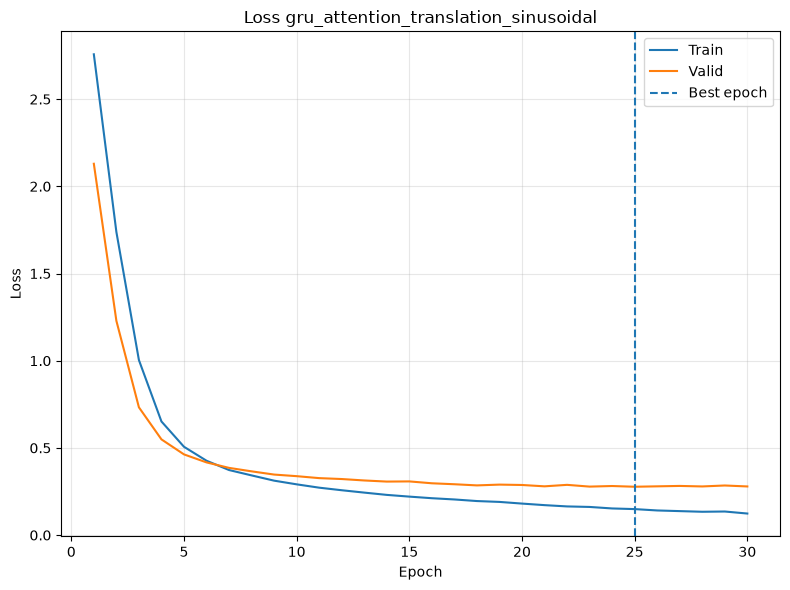

Experiment: gru_attention_translation_sinusoidal
Best epoch: 25/30 completed
Best validation loss: 0.2774
Test loss: 0.2595
Test perplexity: 1.2963


In [26]:
callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

sinusoidal_attention_seq2seq_result = run(
    name='gru_attention_translation_sinusoidal',
    suggest_params=suggest_attention_params,
    build_model=build_attention_translation_model,
    fixed_model_params=sinusoidal_translation_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[sinusoidal_attention_seq2seq_result['name']] = sinusoidal_attention_seq2seq_result

## Position encoding with trainable weights

### Encoder

In [27]:
learned_encoder_params = {
    'vocab_size': len(latin_to_id),
    'pad_idx': latin_to_id['<PAD>'],
    'positional_encoding': 'learned',
}


Experiment: encoder_gru_learned


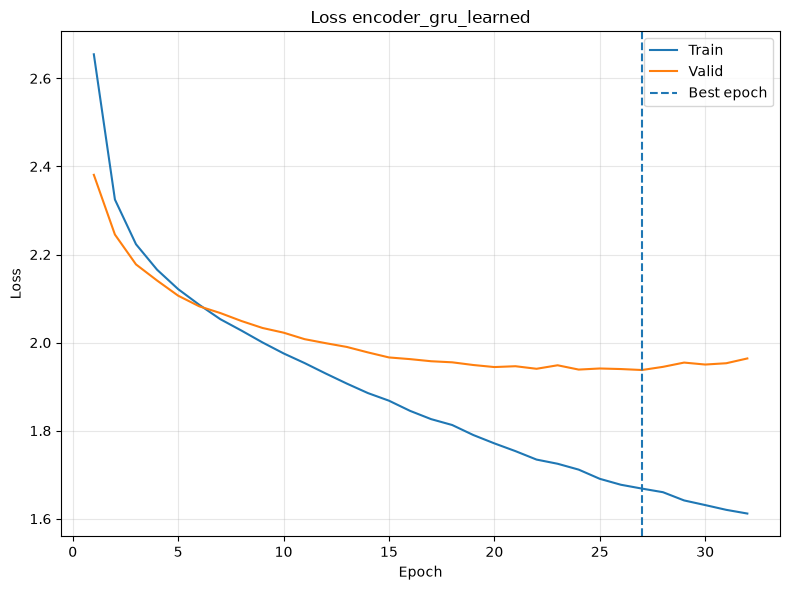

Experiment: encoder_gru_learned
Best epoch: 27/32 completed
Best validation loss: 1.9377
Test loss: 1.9753
Test perplexity: 7.2088


In [28]:
learned_encoder_result = run(
    name='encoder_gru_learned',
    suggest_params=suggest_encoder_params,
    build_model=Encoder,
    fixed_model_params=learned_encoder_params,
    loaders=loaders,
    step_fn=generation_step,
    pad_idx=latin_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
)

## decoder with learned PE

In [29]:
learned_translation_params = {
    'pretrained_encoder': learned_encoder_result['model'],
    'vocab_size': len(cyrillic_to_id),
    'pad_idx': cyrillic_to_id['<PAD>'],
    'positional_encoding': 'learned',
}

### seq2seq


Experiment: gru_translation_learned


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20
train,dijon,дижон,дейтон,дикон,дикон,дижон
train,linden,линден,дейнен,динден,динне,линден
train,stoney,стоуни,дони,стони,стони,стоуни
train,rhea,рея,рула,река,рея,рея
train,worley,уорли,хорли,хорли,хорли,хорли
valid,jameson,джеймсон,джертен,джермисон,дженмисон,наместон
valid,tyrel,тайрел,терел,тайрел,тайрел,тайрель
valid,eleonore,элеонора,оленори,элеонер,элеонсер,элеонор
valid,madelyn,меделин,дерлин,мейлин,мерилин,мэдилин
valid,jewell,джуэлл,джерли,дженелл,дженелл,джезелл


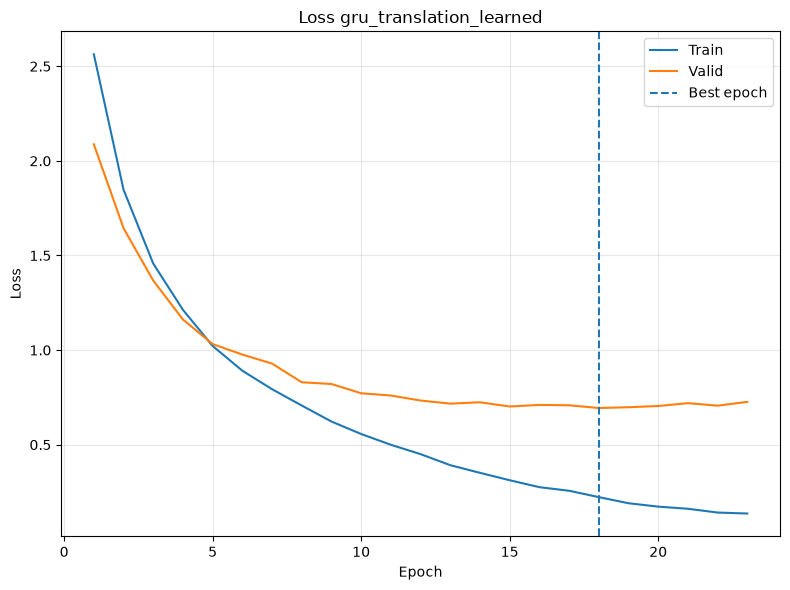

Experiment: gru_translation_learned
Best epoch: 18/23 completed
Best validation loss: 0.6939
Test loss: 0.6494
Test perplexity: 1.9144


In [30]:
callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

learned_seq2seq_result = run(
    name='gru_translation_learned',
    suggest_params=suggest_encoder_params,
    build_model=build_translation_model,
    fixed_model_params=learned_translation_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[learned_seq2seq_result['name']] = learned_seq2seq_result

### attention seq2seq


Experiment: gru_attention_translation_learned


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20,Epoch 25,Epoch 30
train,dijon,дижон,дидон,дидон,диджон,диджон,диджон,диджон
train,linden,линден,линден,линден,линден,линден,линден,линден
train,stoney,стоуни,стони,стони,стони,стони,стоуни,стоуни
train,rhea,рея,рейа,реа,рей,рея,рея,рея
train,worley,уорли,уорли,уорли,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джемейнон,джамейн,джамесон,джамесон,джамесон,джамесон
valid,tyrel,тайрел,терел,тайрел,тайрел,тайрел,тайрел,тайрел
valid,eleonore,элеонора,элеонор,элеонор,элеоноре,элеонор,элеоноре,элеоноре
valid,madelyn,меделин,маделин,маделин,мэделин,мэделин,мэделин,маделин
valid,jewell,джуэлл,джейлл,джейлл,джевлл,джевлл,джевлл,джевлл


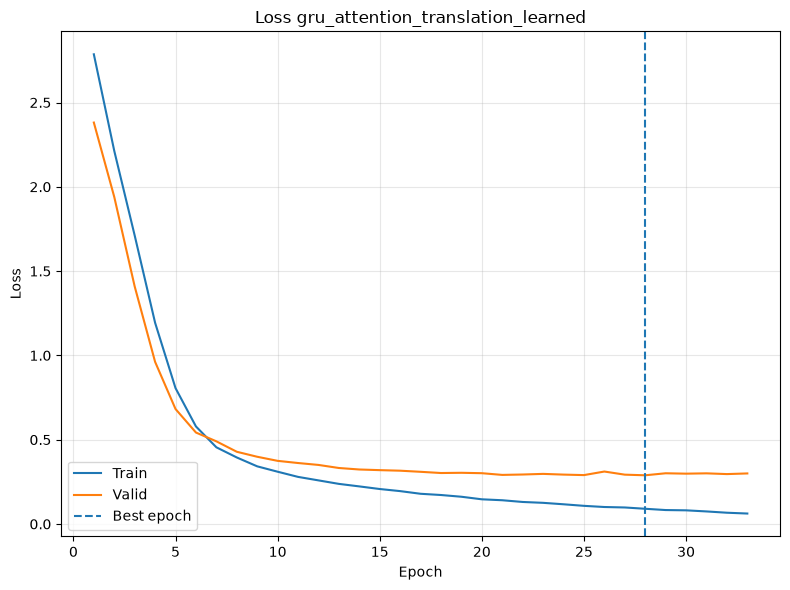

Experiment: gru_attention_translation_learned
Best epoch: 28/33 completed
Best validation loss: 0.2889
Test loss: 0.2636
Test perplexity: 1.3016


In [31]:
callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

learned_attention_seq2seq_result = run(
    name='gru_attention_translation_learned',
    suggest_params=suggest_attention_params,
    build_model=build_attention_translation_model,
    fixed_model_params=learned_translation_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[learned_attention_seq2seq_result['name']] = learned_attention_seq2seq_result

### Visualization of the learned positional encoding

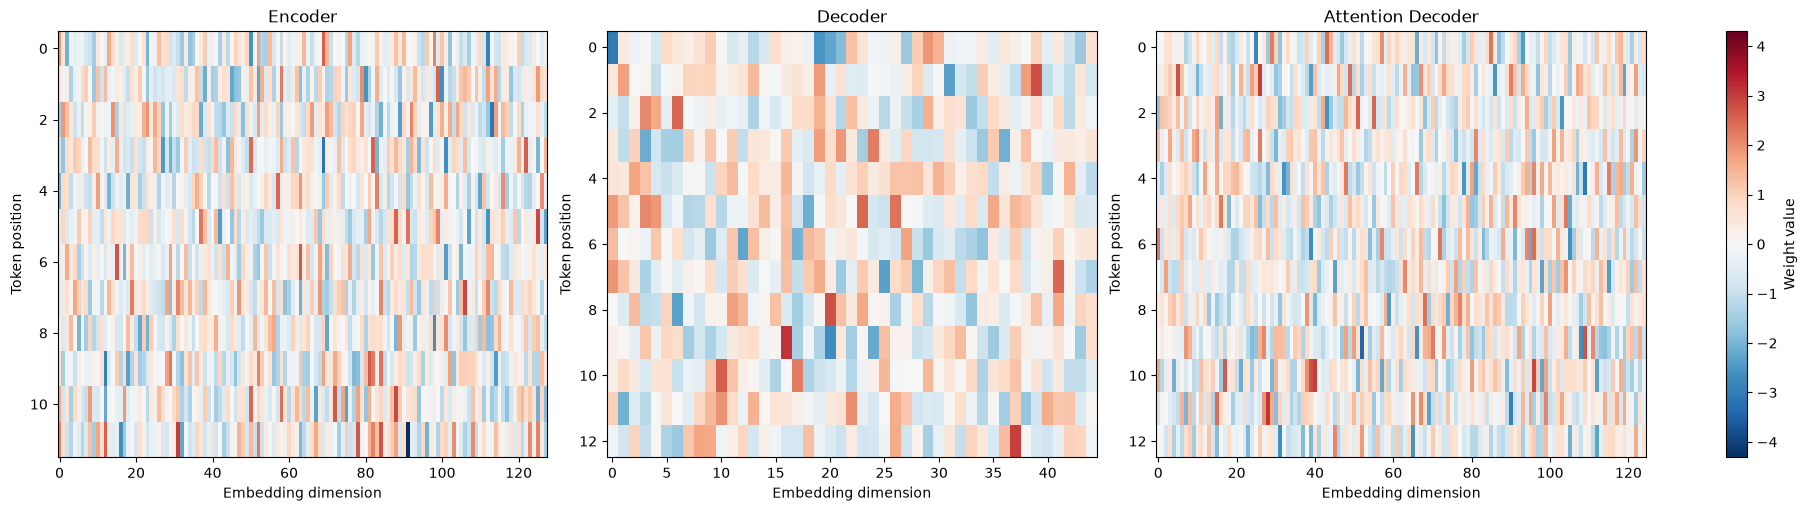

In [32]:
encoder_weights = learned_encoder_result['model'].positional_encoding.position_embedding.weight
decoder_weights = learned_seq2seq_result['model'].decoder.positional_encoding.position_embedding.weight
attention_decoder_weights = learned_attention_seq2seq_result['model'].decoder.positional_encoding.position_embedding.weight


plot_positional_encoding([
    (encoder_weights, max_latin + 1, 'Encoder'),
    (decoder_weights, max_cyrillic + 1, 'Decoder'),
    (attention_decoder_weights, max_cyrillic + 1, 'Attention Decoder')
])

### Visualization of the attention matrix

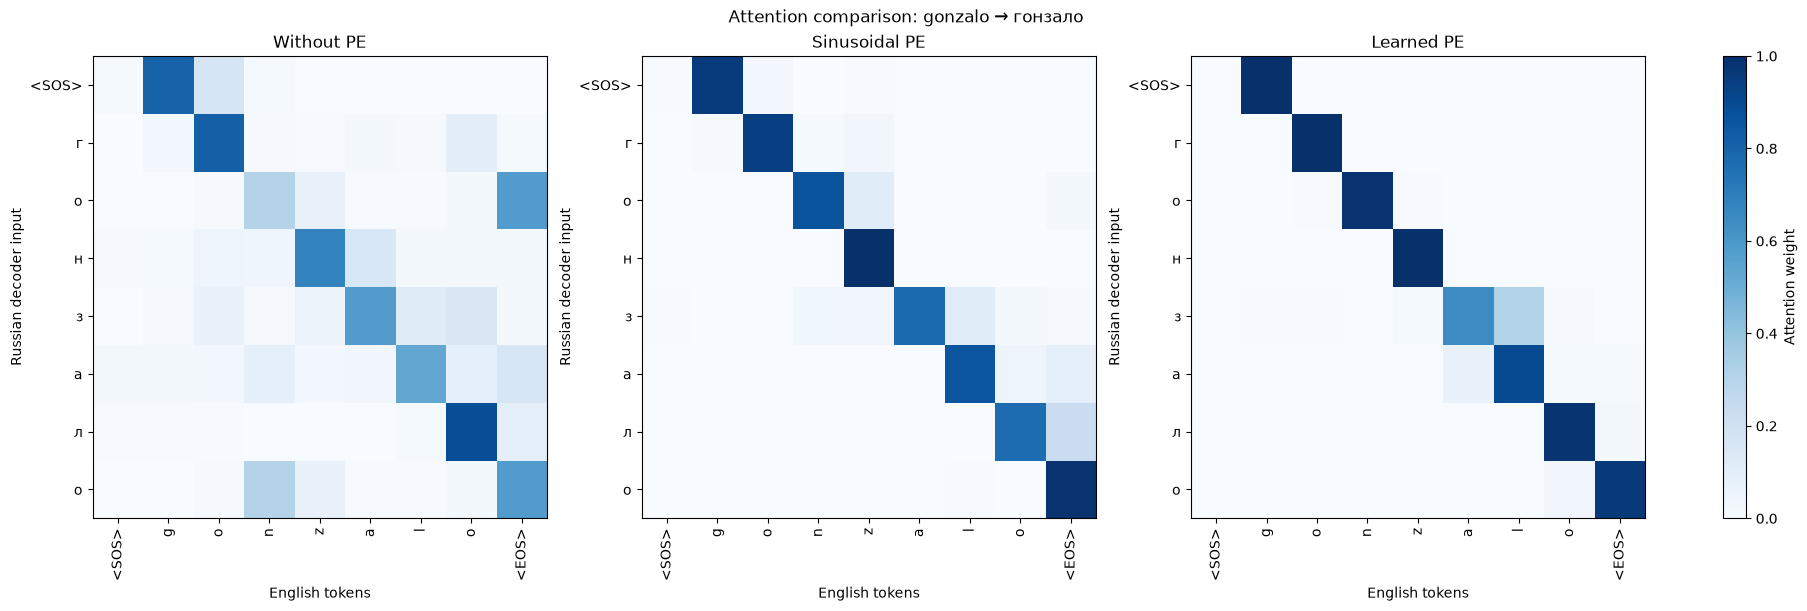

In [33]:
name = 'gonzalo'
translation = 'гонзало'

models_to_compare = [
    ('Without PE', attention_seq2seq_result['model']),
    ('Sinusoidal PE', sinusoidal_attention_seq2seq_result['model']),
    ('Learned PE', learned_attention_seq2seq_result['model']),
]

all_weights = []
titles = []

for label, model in models_to_compare:
    weights, source_tokens, query_tokens = model.get_attention(
        name=name,
        translation=translation,
        latin_to_id=latin_to_id,
        cyrillic_to_id=cyrillic_to_id,
    )

    all_weights.append(weights)
    titles.append(label)

combined_weights = torch.cat(all_weights, dim=0)

plot_attention(
    weights=combined_weights,
    source_tokens=source_tokens,
    query_tokens=query_tokens,
    title=f'Attention comparison: {name} → {translation}',
    subplot_titles=titles,
)

# Multi-head Attention Machine Translation

In [34]:
name = 'gonzalo'
translation = 'гонзало'

### Multi Attention without PE

In [35]:
attention_callback = make_attention_callback(
    name=name,
    translation=translation,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    every_n_epochs=5,
)

translation_callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

callback = combine_callbacks([
    translation_callback,
    attention_callback,
])

three_head_fixed_params = {
    'pretrained_encoder' : encoder_result['model'],
    'vocab_size' : len(cyrillic_to_id),
    'pad_idx' : cyrillic_to_id['<PAD>'],
    'n_heads' : 3,
}


Experiment: gru_three_head_translation


split,name,expected,Epoch 5,Epoch 10,Epoch 15
train,dijon,дижон,дидидидидидидидид,дидидидидидидидидиди,дижон
train,linden,линден,линден,линден,линден
train,stoney,стоуни,стони,стони,стоуни
train,rhea,рея,рея,реа,рея
train,worley,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джеймесон,джеймсон,джеймсон
valid,tyrel,тайрел,тайрил,тайрел,тайрел
valid,eleonore,элеонора,элеонор,элеореор,элеонор
valid,madelyn,меделин,маделин,мэделин,мэделин
valid,jewell,джуэлл,джелл,джуэлл,джуэлл


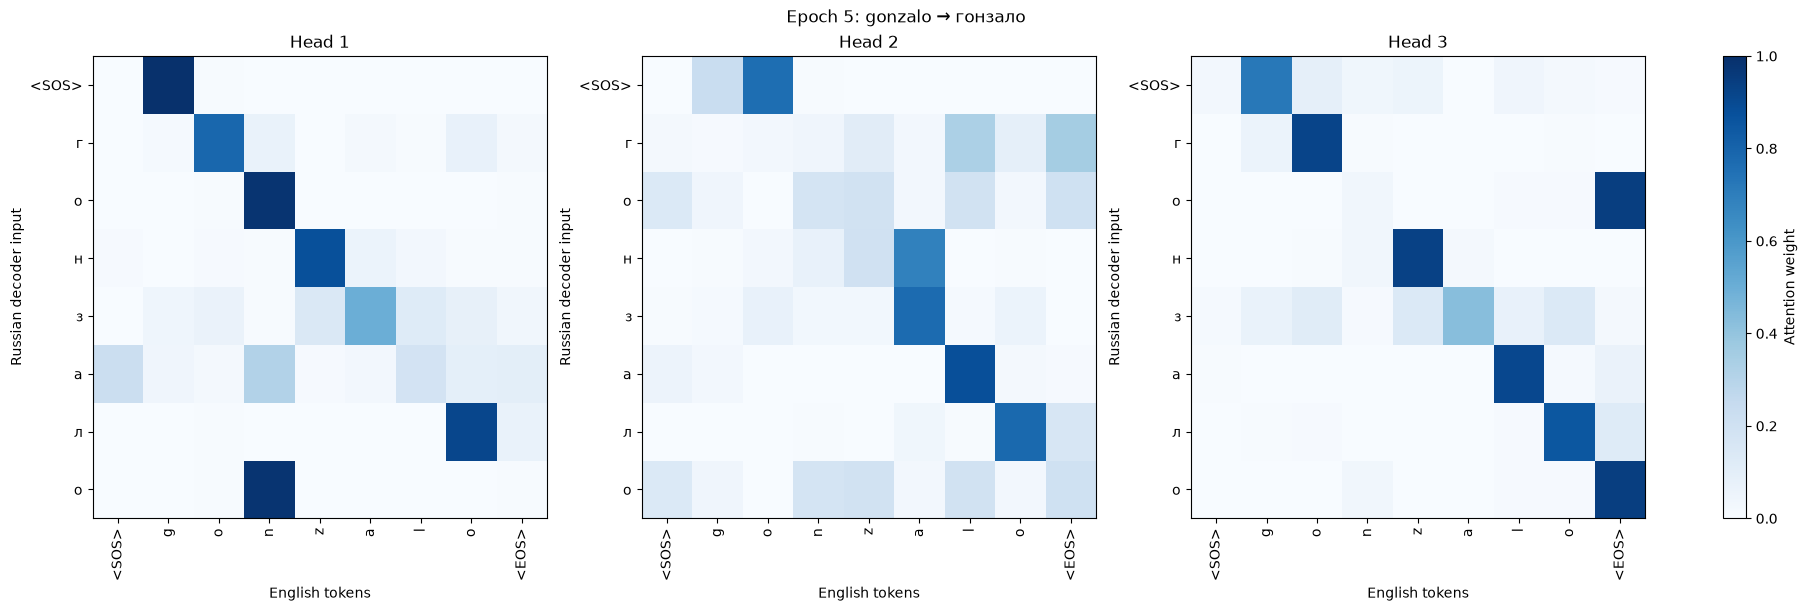

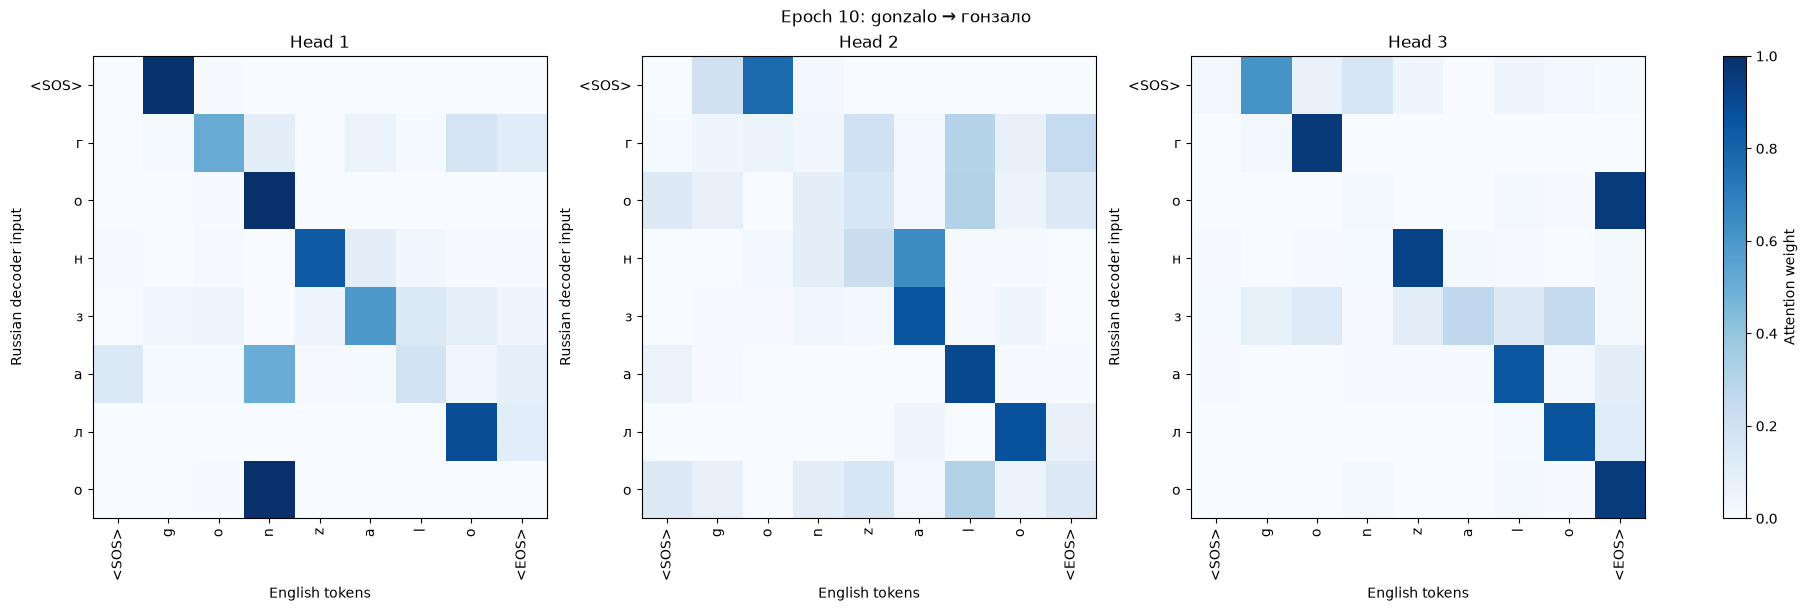

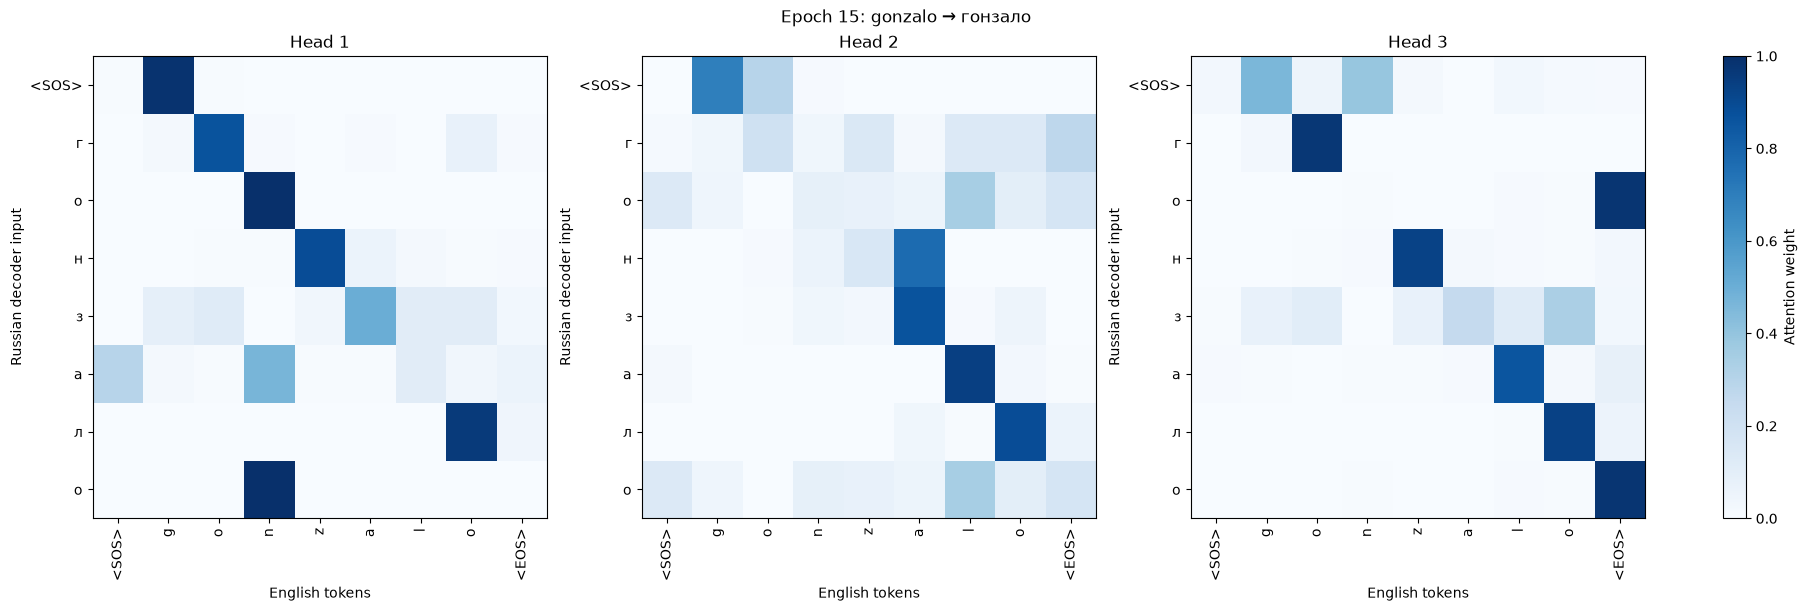

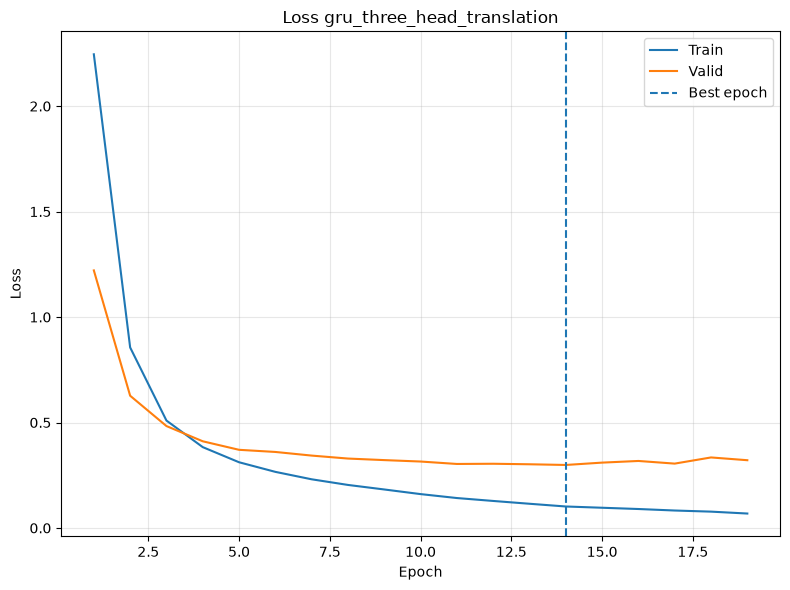

Experiment: gru_three_head_translation
Best epoch: 14/19 completed
Best validation loss: 0.2988
Test loss: 0.2867
Test perplexity: 1.3320


In [36]:
three_head_attention_seq2seq_result = run(
    name='gru_three_head_translation',
    suggest_params=suggest_attention_params,
    build_model=build_attention_translation_model,
    fixed_model_params=three_head_fixed_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[three_head_attention_seq2seq_result['name']] = three_head_attention_seq2seq_result

### Multi Attention with sinusoidal PE

In [37]:
attention_callback = make_attention_callback(
    name=name,
    translation=translation,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    every_n_epochs=5,
)

translation_callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

callback = combine_callbacks([
    translation_callback,
    attention_callback,
])

three_head_sinusoidal_fixed_params = {
    'pretrained_encoder': sinusoidal_encoder_result['model'],
    'vocab_size': len(cyrillic_to_id),
    'pad_idx': cyrillic_to_id['<PAD>'],
    'positional_encoding': 'sinusoidal',
    'n_heads' : 3,
}


Experiment: gru_three_head_sinusoidal_translation


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20
train,dijon,дижон,диджон,диджон,диджон,диджон
train,linden,линден,линден,линден,линден,линден
train,stoney,стоуни,стони,стони,стони,стони
train,rhea,рея,реа,рейр,реа,рея
train,worley,уорли,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джамесон,джамесон,джеймсон,джеймсон
valid,tyrel,тайрел,тайрел,тайрел,тайрел,тайрел
valid,eleonore,элеонора,элеоноре,элеонор,элеонор,элеонор
valid,madelyn,меделин,мэделин,мэделин,мэделин,мэделин
valid,jewell,джуэлл,джеллл,джелл,джелл,джуэлл


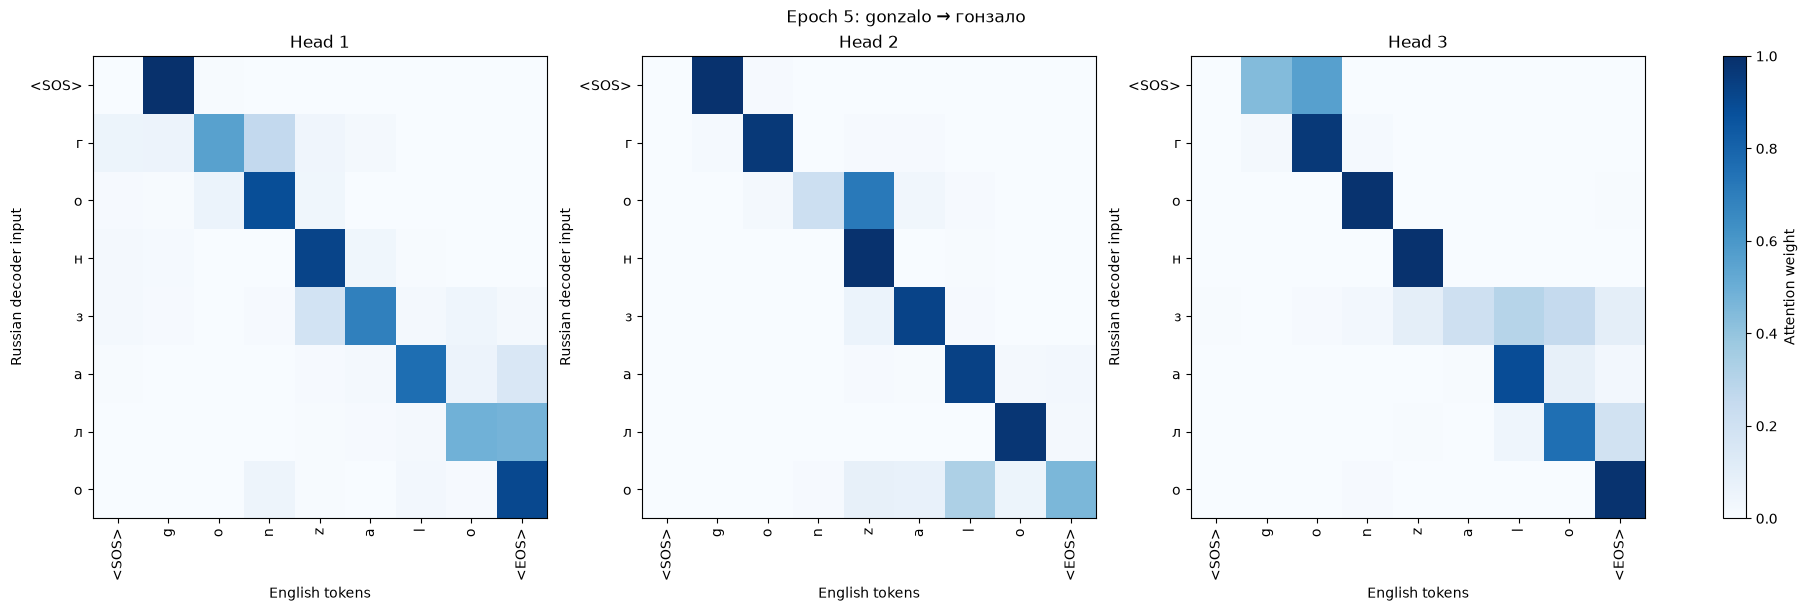

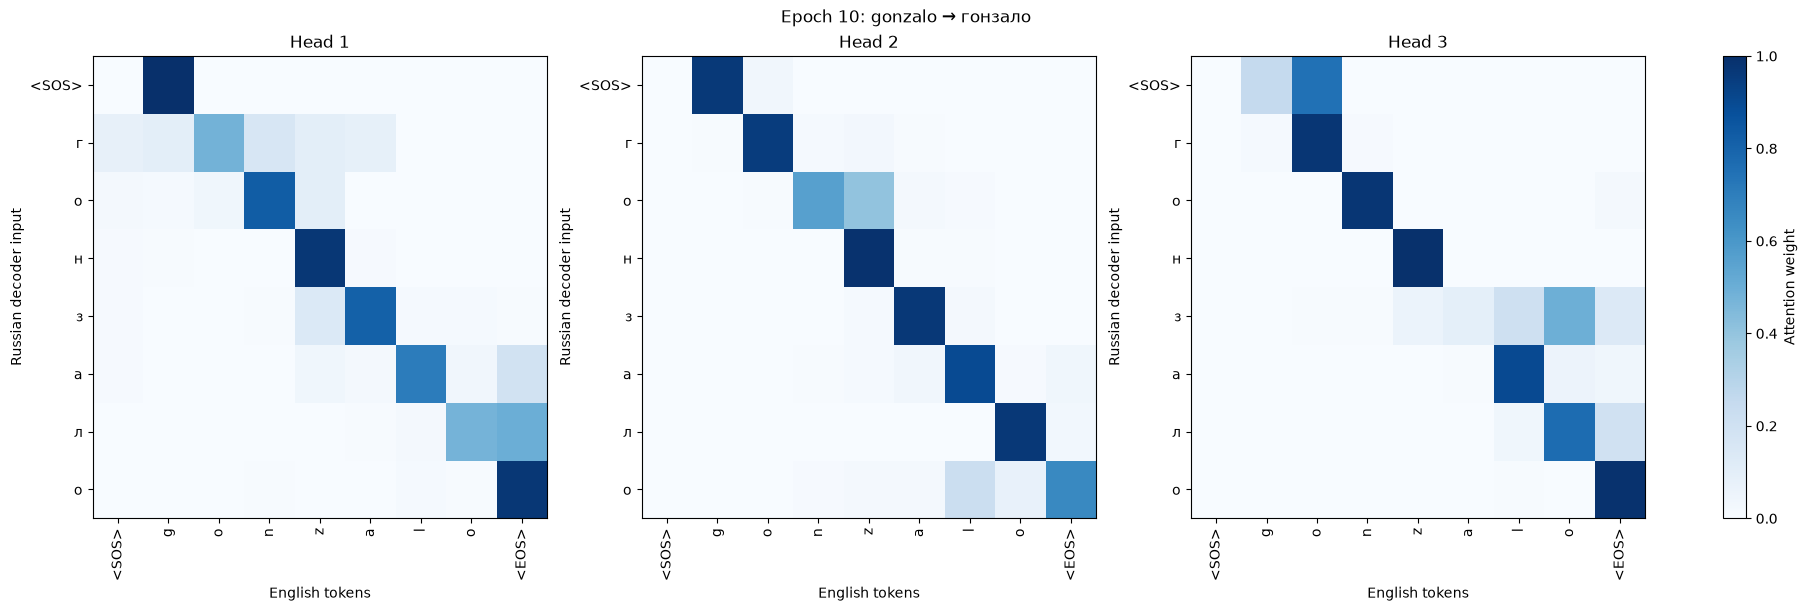

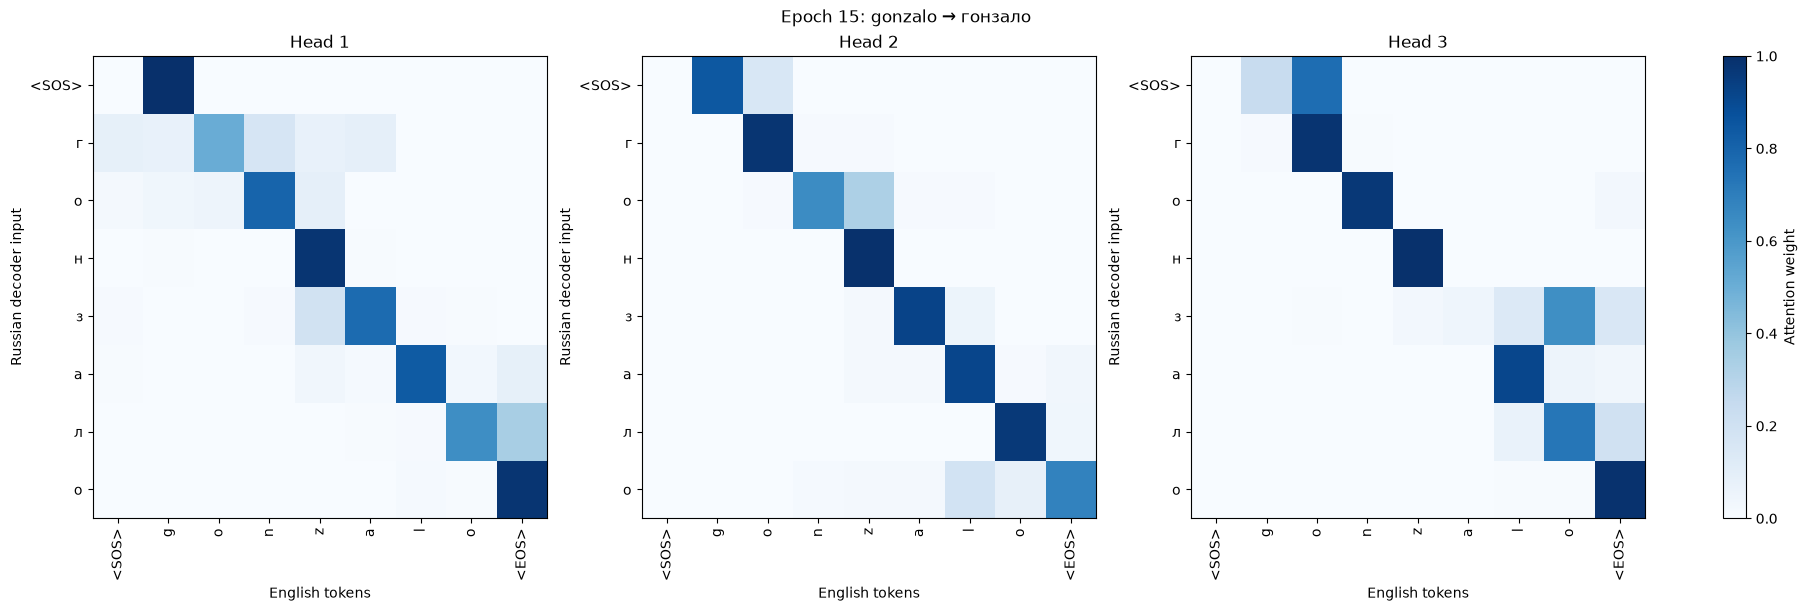

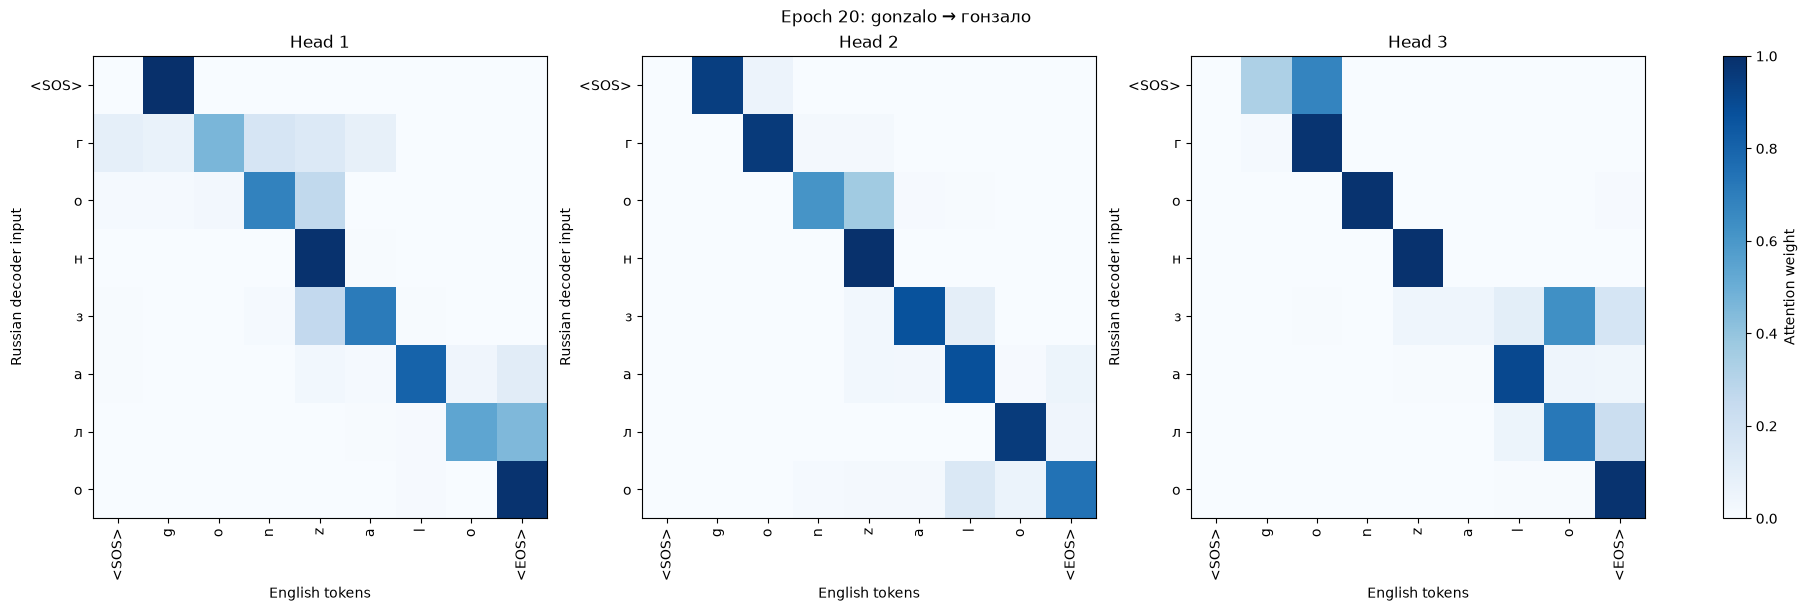

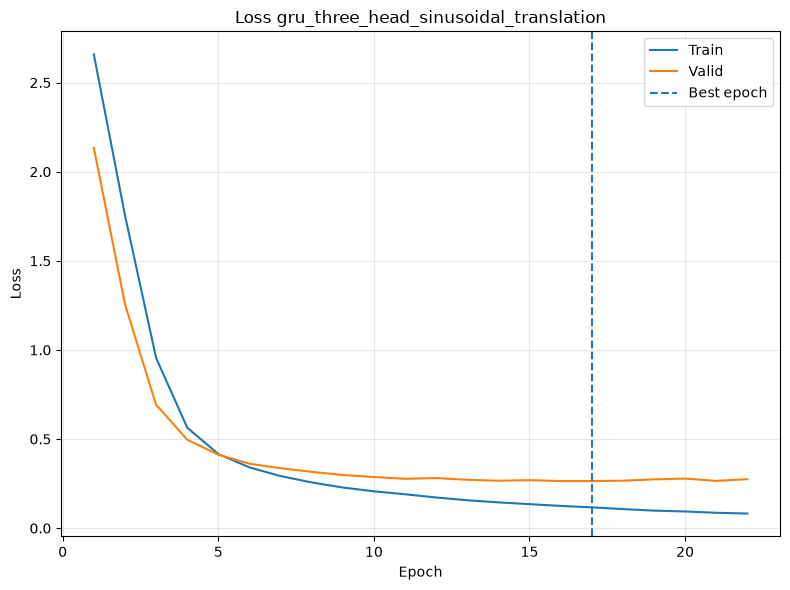

Experiment: gru_three_head_sinusoidal_translation
Best epoch: 17/22 completed
Best validation loss: 0.2641
Test loss: 0.2477
Test perplexity: 1.2810


In [38]:
three_head_sinusoidal_attention_seq2seq_result = run(
    name='gru_three_head_sinusoidal_translation',
    suggest_params=suggest_attention_params,
    build_model=build_attention_translation_model,
    fixed_model_params=three_head_sinusoidal_fixed_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[three_head_sinusoidal_attention_seq2seq_result['name']] = three_head_sinusoidal_attention_seq2seq_result

### Multi Attention with learned PE

In [39]:
attention_callback = make_attention_callback(
    name=name,
    translation=translation,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    every_n_epochs=5,
)

translation_callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

callback = combine_callbacks([
    translation_callback,
    attention_callback,
])

three_head_learned_fixed_params = {
    'pretrained_encoder': learned_encoder_result['model'],
    'vocab_size': len(cyrillic_to_id),
    'pad_idx': cyrillic_to_id['<PAD>'],
    'positional_encoding': 'learned',
    'n_heads' : 3,
}


Experiment: gru_three_head_learned_translation


split,name,expected,Epoch 5,Epoch 10,Epoch 15
train,dijon,дижон,диджон,дижон,дижон
train,linden,линден,линден,линден,линден
train,stoney,стоуни,стони,стоуни,стоуни
train,rhea,рея,рей,рея,рея
train,worley,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джамесон,джамсон,джеймсон
valid,tyrel,тайрел,тайрел,тайрел,тайрел
valid,eleonore,элеонора,элеонор,элеонор,элеонор
valid,madelyn,меделин,мэделин,мэделин,мэделин
valid,jewell,джуэлл,джевелл,джевелл,джуэлл


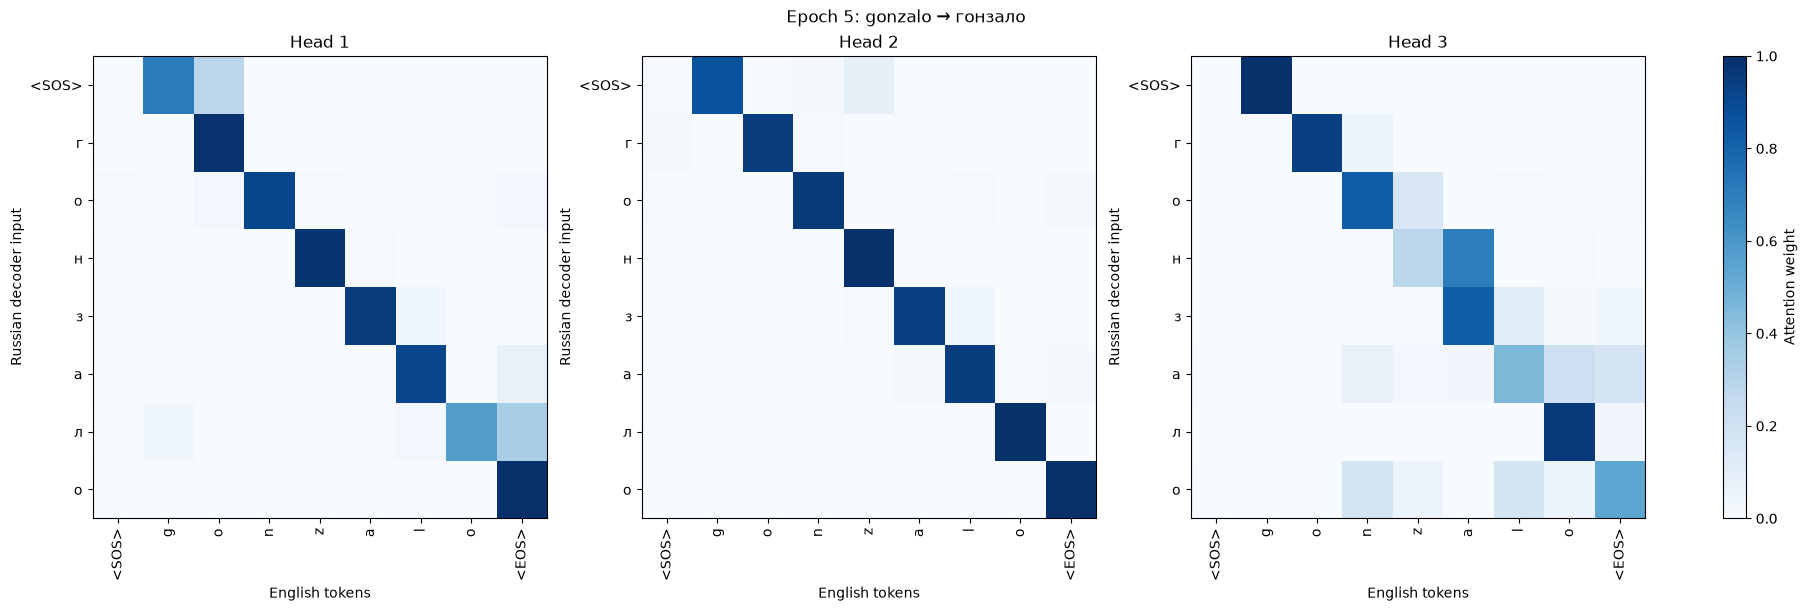

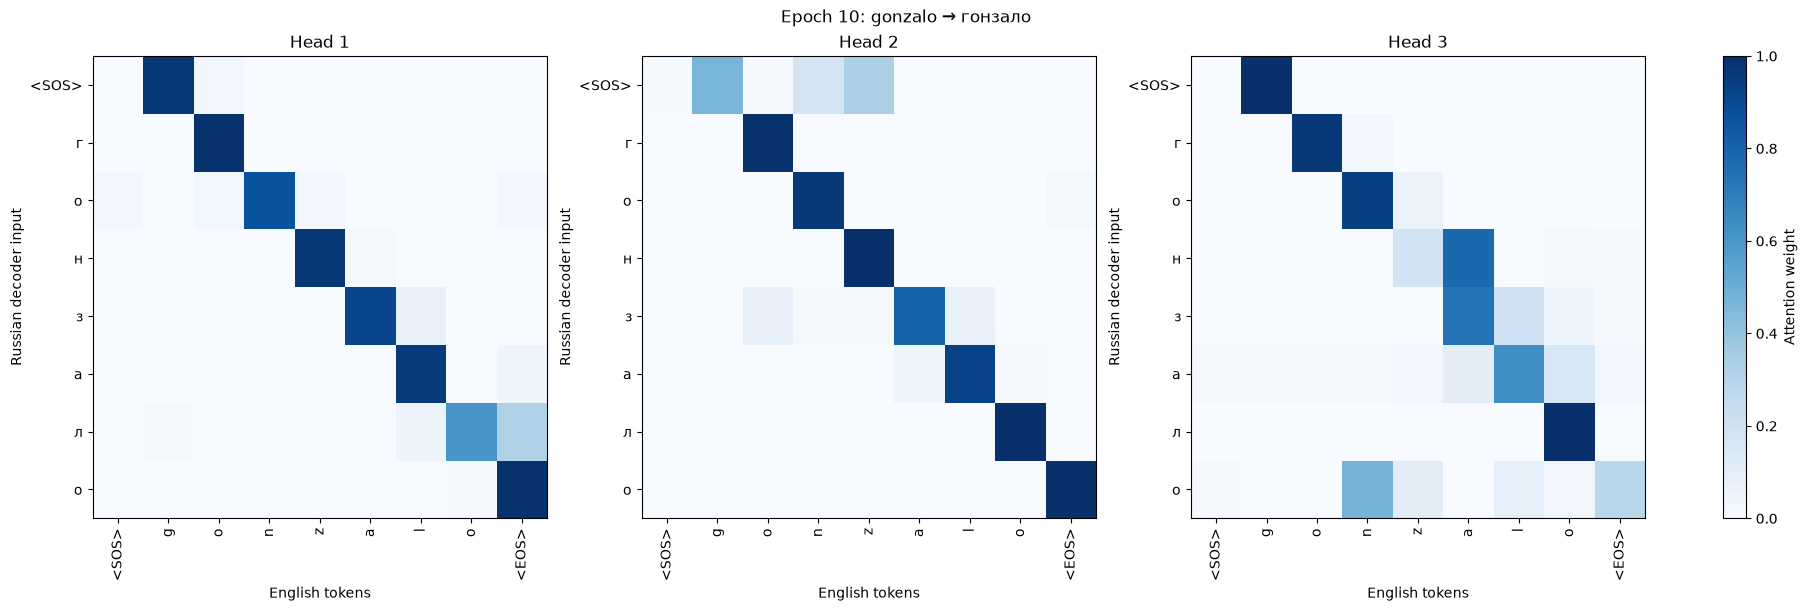

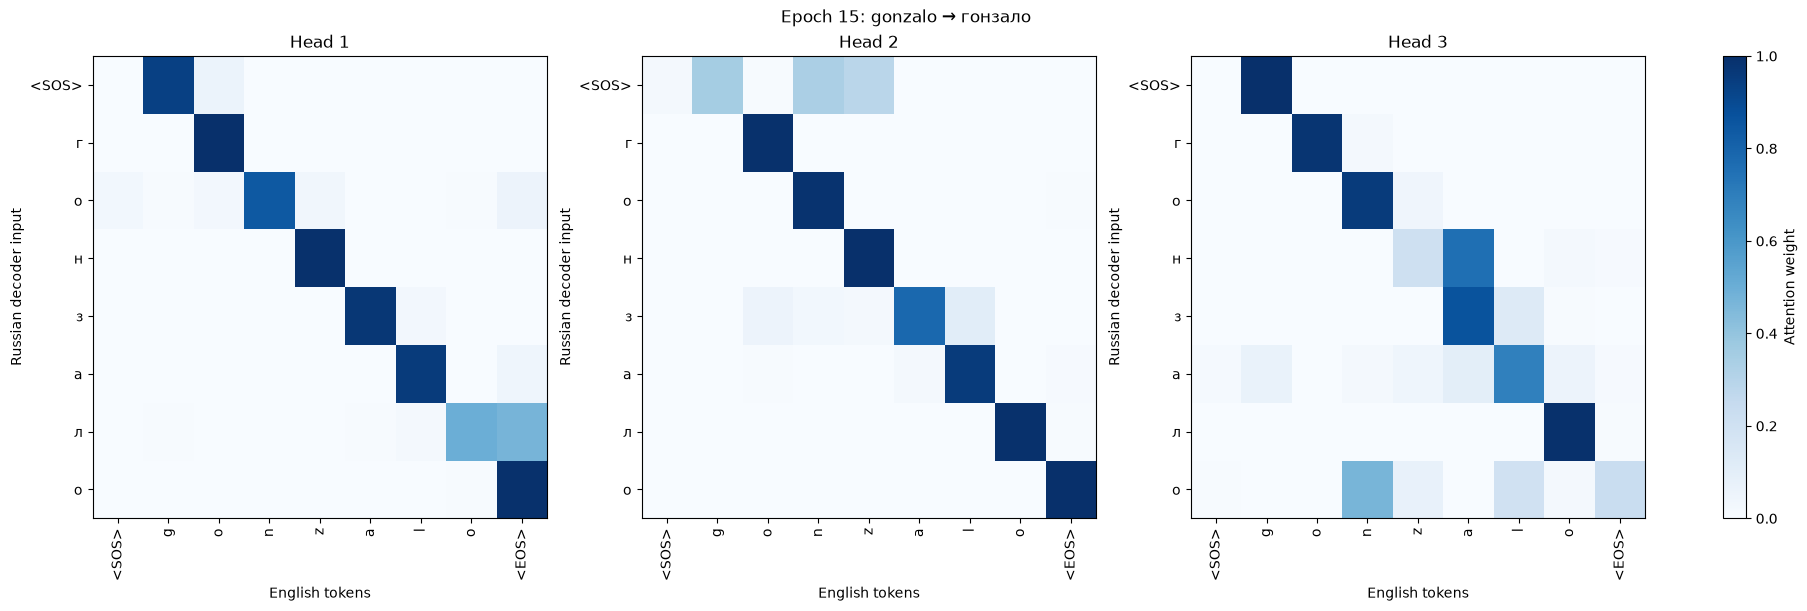

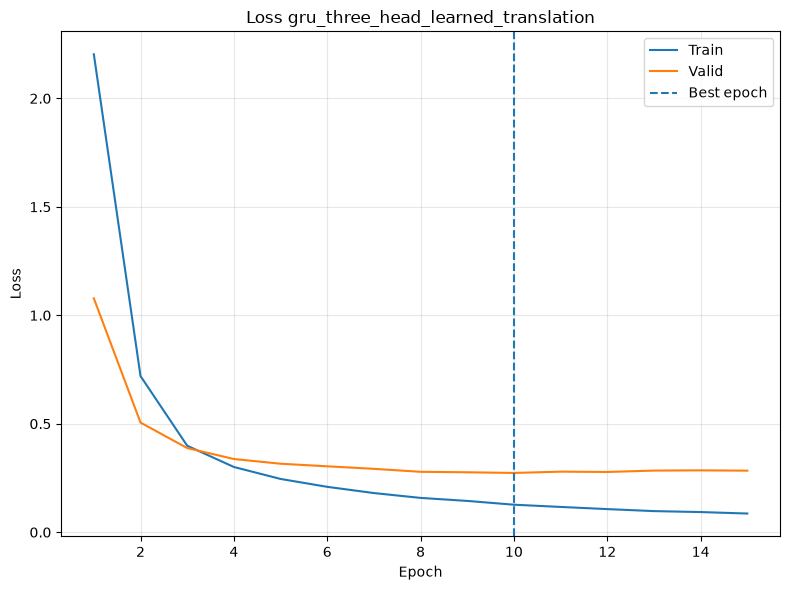

Experiment: gru_three_head_learned_translation
Best epoch: 10/15 completed
Best validation loss: 0.2731
Test loss: 0.2569
Test perplexity: 1.2929


In [40]:
three_head_learned_attention_seq2seq_result = run(
    name='gru_three_head_learned_translation',
    suggest_params=suggest_attention_params,
    build_model=build_attention_translation_model,
    fixed_model_params=three_head_learned_fixed_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[three_head_learned_attention_seq2seq_result['name']] = three_head_learned_attention_seq2seq_result

# Transformer Architecture

In [41]:
translation_callback = make_translation_callback(
    train_df=df_train,
    valid_df=df_valid,
    latin_to_id=latin_to_id,
    cyrillic_to_id=cyrillic_to_id,
    id_to_cyrillic=id_to_cyrillic,
    random_state=21,
    every_n_epochs=5,
)

callback = combine_callbacks([
    translation_callback,
])

transformer_fixed_params = {
    'source_vocab_size': len(latin_to_id),
    'target_vocab_size': len(cyrillic_to_id),
    'source_pad_idx': latin_to_id['<PAD>'],
    'target_pad_idx': cyrillic_to_id['<PAD>'],
    'positional_encoding': 'sinusoidal',
    'max_len': 64,
}


Experiment: transformer_sinusoidal


split,name,expected,Epoch 5,Epoch 10,Epoch 15,Epoch 20,Epoch 25
train,dijon,дижон,диджон,диджон,диджон,диджон,диджон
train,linden,линден,линден,линден,линден,линден,линден
train,stoney,стоуни,стони,стони,стони,стони,стони
train,rhea,рея,рейя,рейя,реа,реа,реа
train,worley,уорли,уорли,уорли,уорли,уорли,уорли
valid,jameson,джеймсон,джемесон,джеймен,джамесон,джамесон,джеймсон
valid,tyrel,тайрел,тайрл,тайрел,тайрел,тайрел,тайрел
valid,eleonore,элеонора,элеонор,элеонор,элеонор,элеонор,элеонор
valid,madelyn,меделин,маделин,мэделин,мэделин,мэделин,мэделин
valid,jewell,джуэлл,джевлл,джуэлл,джуэлл,джуэлл,джуэлл


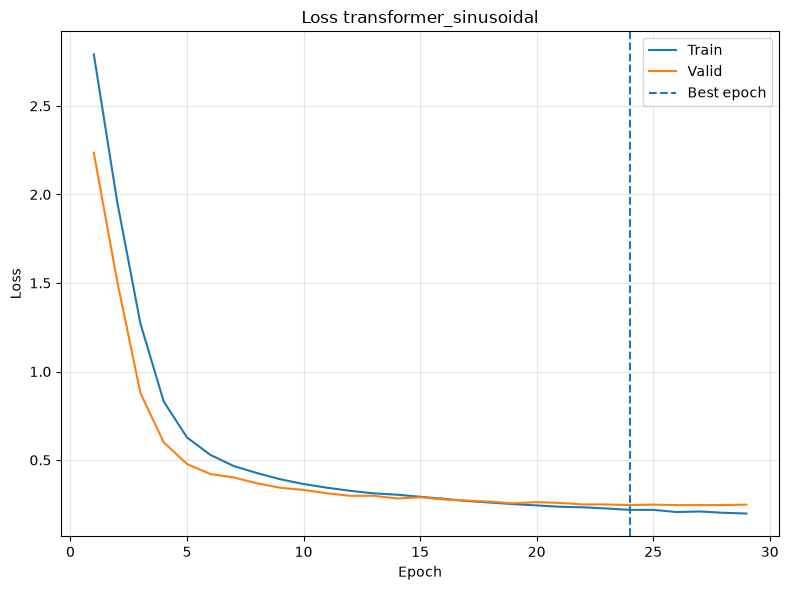

Experiment: transformer_sinusoidal
Best epoch: 24/29 completed
Best validation loss: 0.2456
Test loss: 0.2291
Test perplexity: 1.2575


In [42]:
transformer_result = run(
    name='transformer_sinusoidal',
    suggest_params=suggest_transformer_params,
    build_model=TransformerSeq2Seq,
    fixed_model_params=transformer_fixed_params,
    loaders=loaders,
    step_fn=translation_step,
    pad_idx=cyrillic_to_id['<PAD>'],
    train_config=train_config,
    search_config=search_config,
    plot=True,
    on_epoch_end=callback,
)

results[transformer_result['name']] = transformer_result

# RESULTS

In [43]:
summarize_results(results)

,experiment,best_epoch,epochs_completed,train_loss,valid_loss,gap,test_loss,test_perplexity
9,transformer_sinusoidal,24,29,0.218595,0.245622,0.027026,0.229099,1.257466
7,gru_three_head_sinusoidal_translation,17,22,0.116746,0.264070,0.147324,0.247676,1.281045
8,gru_three_head_learned_translation,10,15,0.126742,0.273135,0.146393,0.256879,1.292888
3,gru_attention_translation_sinusoidal,25,30,0.149186,0.277351,0.128165,0.259499,1.296280
5,gru_attention_translation_learned,28,33,0.090204,0.288863,0.198659,0.263615,1.301627
6,gru_three_head_translation,14,19,0.101950,0.298820,0.196870,0.286684,1.332003
1,gru_attention_translation,27,32,0.134001,0.316428,0.182427,0.300436,1.350447
0,gru_translation,27,32,0.234122,0.633965,0.399843,0.589162,1.802478
2,gru_translation_sinusoidal,15,20,0.259016,0.611256,0.352240,0.599839,1.821826
4,gru_translation_learned,18,23,0.223007,0.693896,0.470888,0.649414,1.914419


The project explored name transliteration using GRU encoder–decoder models, attention, positional encoding, and a Transformer.

Attention provided the largest improvement over the basic GRU model. Sinusoidal positional encoding improved results across the tested architectures, while learned positions were less consistent. Adding more attention heads brought a smaller improvement.

The Transformer achieved the lowest validation and test loss, the lowest test perplexity, and the smallest gap between training and validation loss. It showed the strongest generalization in these experiments, although it required more training epochs.

Overall, the results show that access to the full encoder sequence through attention was more beneficial than relying only on a final hidden state.

# Save Translation model 

In [45]:
import pickle
from pathlib import Path

folder = Path("artifacts")
folder.mkdir(exist_ok=True)

result = results["transformer_sinusoidal"]

artifact = {
    "model": result["model"].cpu().eval(),
    "latin_to_id": latin_to_id,
    "id_to_latin": id_to_latin,
    "cyrillic_to_id": cyrillic_to_id,
    "id_to_cyrillic": id_to_cyrillic,
    "random_state": 21,
}

path = folder / f"{result['name']}.pkl"

with path.open("wb") as file:
    pickle.dump(artifact, file)

print(f"Saved: {path}")

Saved: artifacts/transformer_sinusoidal.pkl


# LOAD AND CHECK

In [46]:
with open(
    "artifacts/transformer_sinusoidal.pkl", "rb"
) as file:
    artifact = pickle.load(file)

loaded_model = artifact["model"]
loaded_model.eval()

TransformerSeq2Seq(
  (source_embedding): Embedding(29, 128, padding_idx=0)
  (target_embedding): Embedding(34, 128, padding_idx=0)
  (source_positional_encoding): SinusoidalPositionalEncoding()
  (target_positional_encoding): SinusoidalPositionalEncoding()
  (encoder_layers): ModuleList(
    (0-1): 2 x TransformerEncoderLayer(
      (self_attention): MultiHeadAttention(
        (heads): ModuleList(
          (0-1): 2 x Attention(
            (query_projection): Linear(in_features=128, out_features=64, bias=False)
            (key_projection): Linear(in_features=128, out_features=64, bias=False)
            (value_projection): Linear(in_features=128, out_features=64, bias=False)
          )
        )
        (projection): Linear(in_features=128, out_features=128, bias=False)
      )
      (feedforward): FeedForward(
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (activation): ReLU()
        (linear2): Linear(in_features=256, out_features=128, bias=True)

In [47]:
predictions = []

for name in df_test["latin"]:
    prediction = loaded_model.translate(
        name=name,
        latin_to_id=artifact["latin_to_id"],
        cyrillic_to_id=artifact["cyrillic_to_id"],
        id_to_cyrillic=artifact["id_to_cyrillic"],
    )
    predictions.append(prediction)

test_predictions = pd.DataFrame({
    "latin": df_test["latin"].to_list(),
    "expected": df_test["cyrillic"].to_list(),
    "predicted": predictions,
})

test_predictions.to_csv(
    "artifacts/test_predictions.csv",
    index=False,
)

test_predictions.head()

,latin,expected,predicted
0,arnie,арни,арни
1,jefferson,джефферсон,джеффресон
2,brodie,броди,броди
3,mario,марио,марио
4,alpha,альфа,альфа
